# FeliX Crop Yield and Subscripted Variables

Grain yield corresponds to **`Crop yield for each category[Grains]`**. Its Python output column is `crop_yield_for_each_category[Grains]`.

This notebook loads `output/FeliX3_ISE_v26_final_fixed.py`, retains the default parameters and original integration time step, and runs from 1900 to 2100 with annual outputs. It requests agricultural outputs only and does not modify the model or request the YoGL life-table variables affected by self-reference errors.

Run from this notebook's directory using a Python kernel with `pysd numpy pandas xarray matplotlib ipykernel` installed. Execute the cells in order. Each figure has a separate plotting cell, without plotting loops.

In [1]:
%matplotlib inline
from pathlib import Path
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
import pysd
import matplotlib.pyplot as plt
from IPython.display import display

# The model file is in the output folder beside this notebook.
model_path = Path("output/FeliX3_ISE_v26_final_fixed.py").resolve()
warnings.simplefilter("once", UserWarning)
model = pysd.load(model_path)
c = model.components

print(f"PySD: {pysd.__version__}")
print(f"Model: {model_path}")
print(f"Time: {c.initial_time()}–{c.final_time()}, dt={c.time_step()}")

f:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\.venv\Lib\site-packages\pysd\py_backend\lookups.py:108: UserWarning: _hardcodedlookup_lookup_for_the_impact_of_mys_on_climate_mortality
extrapolating data below the minimum value of the series
  warnings.warn(


PySD: 3.14.3
Model: F:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\output\FeliX3_ISE_v26_final_fixed.py
Time: 1900–2100, dt=0.125


f:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\.venv\Lib\site-packages\pysd\py_backend\lookups.py:108: UserWarning: _hardcodedlookup_effect_of_t_on_yield_lookup
extrapolating data below the minimum value of the series
  warnings.warn(


## 1. Understand crop subscripts

`PlantFood` contains four crop categories: Pulses, Grains, VegFruits (vegetables and fruits), and OtherCrops. A subscripted variable holds one value per category; `Grains` selects one entry.

Before simulation, use `.sel(PlantFood="Grains")` to select grain yield by label. After simulation, PySD expands subscripts into columns. Use `result["crop_yield_for_each_category[Grains]"]` to read the simulated time series.

Yield is measured in `Ton/(ha*Year)`, production in `Ton/Year`, and harvested area in `ha`. Fertilizer effects are dimensionless multipliers; 1 is the neutral value.

In [2]:
print("PlantFood:", model.subscripts["PlantFood"]) # List the crop categories defined in the model.

# These are the four initial crop yields, not the simulated time series.
initial_yield = c.crop_yield_for_each_category()
display(initial_yield)

# Select the grain category by its coordinate label.
initial_grain_yield = initial_yield.sel(PlantFood="Grains")
print("Initial grain yield:", float(initial_grain_yield))

PlantFood: ['Pulses', 'Grains', 'VegFruits', 'OtherCrops']


<xarray.DataArray (PlantFood: 4)> Size: 32B
array([0.39941489, 1.14773967, 5.77860565, 3.53757902])
Coordinates:
  * PlantFood  (PlantFood) <U10 160B 'Pulses' 'Grains' 'VegFruits' 'OtherCrops'

Initial grain yield: 1.1477396725858227


## 2. Run the simulation and collect agricultural outputs

`return_columns` explicitly lists the outputs to save. Most variables retain all crop subscripts. The fertilizer effect is requested only for the four crop categories, avoiding undefined slices for other food categories.

`Average expected crop yield` is the 2016 reference yield multiplied by the fertilizer effect. `Expected crop yield` is a separate variable with a delay process. Their original definitions are preserved.

Technology and environmental multipliers are not requested or plotted separately in this notebook. The model still evaluates them internally where required by the original crop-yield equations.

In [3]:
output_variables = [
    "crop_yield_for_each_category", # Crop yields for all four categories.
    "average_expected_crop_yield",
    "expected_crop_yield",
    "reference_crop_yield_2016[Grains]",
    "cereal_yield",
    "cropland_yield",  # Harvested-area-weighted yield with no crop subscript.
    "production_rate_of_crops",
    "area_harvested",
    "effect_of_fertilizer_on_yield[Pulses]",
    "effect_of_fertilizer_on_yield[Grains]",
    "effect_of_fertilizer_on_yield[VegFruits]",
    "effect_of_fertilizer_on_yield[OtherCrops]",
]

years = np.arange(c.initial_time(), c.final_time() + 1, 1)
start = perf_counter()

# Capture lookup-extrapolation warnings; inspect run_warnings if needed.
with warnings.catch_warnings(record=True) as run_warnings:
    result = model.run(
        return_columns=output_variables,
        return_timestamps=years,
        initial_condition="original",
        flatten_output=True,
    )

print(f"Elapsed: {perf_counter() - start:.1f} s")
print(f"Result: {len(result)} years, {len(result.columns)} series")
print(f"Captured warnings: {len(run_warnings)}")
display(result.head())
display(result.tail())


Elapsed: 353.6 s
Result: 201 years, 27 series
Captured warnings: 4134


,crop_yield_for_each_category[Pulses],crop_yield_for_each_category[Grains],crop_yield_for_each_category[VegFruits],crop_yield_for_each_category[OtherCrops],average_expected_crop_yield[Pulses],average_expected_crop_yield[Grains],average_expected_crop_yield[VegFruits],average_expected_crop_yield[OtherCrops],expected_crop_yield[Pulses],expected_crop_yield[Grains],...,production_rate_of_crops[VegFruits],production_rate_of_crops[OtherCrops],area_harvested[Pulses],area_harvested[Grains],area_harvested[VegFruits],area_harvested[OtherCrops],effect_of_fertilizer_on_yield[Pulses],effect_of_fertilizer_on_yield[Grains],effect_of_fertilizer_on_yield[VegFruits],effect_of_fertilizer_on_yield[OtherCrops]
time,,,,,,,,,,,,,,,,,,,,,
1900.0,0.399415,1.147740,5.778606,3.537579,0.714655,2.053600,10.339404,6.329634,0.340000,0.970000,...,1.970530e+08,1.877451e+08,2.181813e+07,2.812298e+08,4.029713e+07,6.279102e+07,0.721874,0.517280,0.683371,0.700956
1901.0,0.400214,1.150008,5.790051,3.544572,0.714622,2.053452,10.338702,6.329180,0.379178,1.087167,...,1.977912e+08,1.884557e+08,1.956199e+07,2.520133e+08,3.611485e+07,5.626979e+07,0.721840,0.517242,0.683325,0.700906
1902.0,0.403406,1.161205,5.844679,3.579001,0.716967,2.063790,10.387649,6.360898,0.394124,1.132490,...,1.991401e+08,1.897327e+08,1.893480e+07,2.436866e+08,3.492793e+07,5.441140e+07,0.724209,0.519846,0.686560,0.704418
1903.0,0.406173,1.170017,5.888278,3.606130,0.717890,2.067947,10.407237,6.373654,0.401179,1.154430,...,2.007718e+08,1.912933e+08,1.875233e+07,2.410572e+08,3.455811e+07,5.382489e+07,0.725141,0.520893,0.687854,0.705831
1904.0,0.408778,1.177996,5.928001,3.630706,0.718361,2.070139,10.417508,6.380382,0.405359,1.167436,...,2.025880e+08,1.930389e+08,1.873352e+07,2.405266e+08,3.449020e+07,5.370936e+07,0.725617,0.521446,0.688533,0.706576


,crop_yield_for_each_category[Pulses],crop_yield_for_each_category[Grains],crop_yield_for_each_category[VegFruits],crop_yield_for_each_category[OtherCrops],average_expected_crop_yield[Pulses],average_expected_crop_yield[Grains],average_expected_crop_yield[VegFruits],average_expected_crop_yield[OtherCrops],expected_crop_yield[Pulses],expected_crop_yield[Grains],...,production_rate_of_crops[VegFruits],production_rate_of_crops[OtherCrops],area_harvested[Pulses],area_harvested[Grains],area_harvested[VegFruits],area_harvested[OtherCrops],effect_of_fertilizer_on_yield[Pulses],effect_of_fertilizer_on_yield[Grains],effect_of_fertilizer_on_yield[VegFruits],effect_of_fertilizer_on_yield[OtherCrops]
time,,,,,,,,,,,,,,,,,,,,,
2096.0,1.242622,5.056332,19.298570,11.845209,0.922700,3.754541,14.330007,8.795571,1.239057,5.037981,...,3.382702e+09,3.696457e+09,8.886228e+07,7.053755e+08,1.755564e+08,3.127567e+08,0.932020,0.945728,0.947125,0.974039
2097.0,1.246137,5.075049,19.356099,11.882233,0.923194,3.759822,14.339859,8.802886,1.242637,5.056564,...,3.378939e+09,3.692344e+09,8.850507e+07,7.020287e+08,1.748270e+08,3.114234e+08,0.932519,0.947059,0.947777,0.974849
2098.0,1.249156,5.092009,19.406125,11.914767,0.923721,3.765420,14.350368,8.810687,1.245991,5.074599,...,3.374962e+09,3.687998e+09,8.815759e+07,6.987447e+08,1.741161e+08,3.101218e+08,0.933052,0.948468,0.948471,0.975713
2099.0,1.251924,5.107850,19.452137,11.944794,0.924216,3.770801,14.360274,8.818081,1.249030,5.091524,...,3.370760e+09,3.683407e+09,8.782729e+07,6.955798e+08,1.734383e+08,3.088775e+08,0.933551,0.949824,0.949126,0.976532
2100.0,1.254562,5.122987,19.495946,11.973388,0.924661,3.775842,14.369278,8.824857,1.251837,5.107453,...,3.366420e+09,3.678664e+09,8.751245e+07,6.925178e+08,1.727897e+08,3.076841e+08,0.934001,0.951094,0.949721,0.977282


## 3. Grain yield and reference values

Compare grain yield, the two expected-yield variables, and the fixed 2016 reference value. The reference line is a parameter, not a historical observation series. The curves have the same units but different definitions.

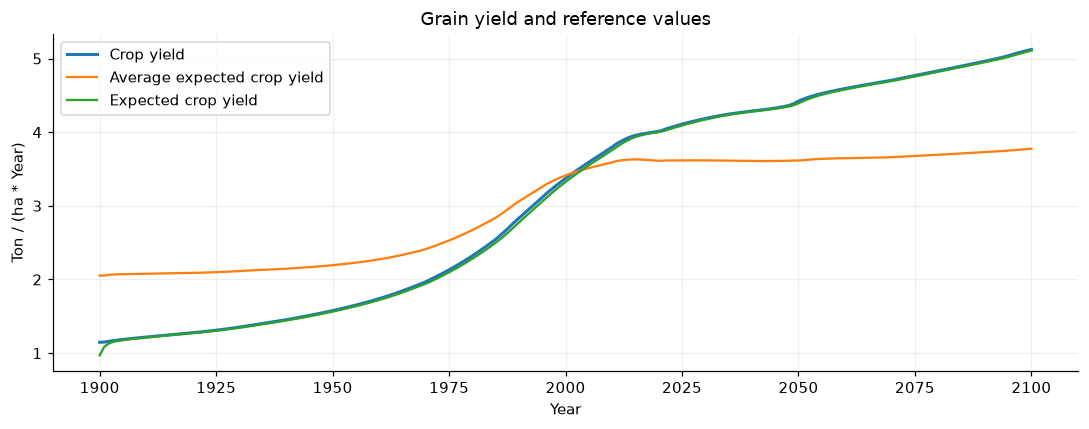

In [11]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

plt.figure(figsize=(10, 4))
plt.plot(result.index, result["crop_yield_for_each_category[Grains]"], label="Crop yield", linewidth=2)
plt.plot(result.index, result["average_expected_crop_yield[Grains]"], label="Average expected crop yield")
plt.plot(result.index, result["expected_crop_yield[Grains]"], label="Expected crop yield")
# plt.plot(result.index, result["reference_crop_yield_2016[Grains]"], label="2016 reference parameter", linestyle="--")
plt.title("Grain yield and reference values")
plt.xlabel("Year")
plt.ylabel("Ton / (ha * Year)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 4. Yield across four crop categories

Plot the four subscripts of `crop_yield_for_each_category`. Grain yield is highlighted with a thicker line.

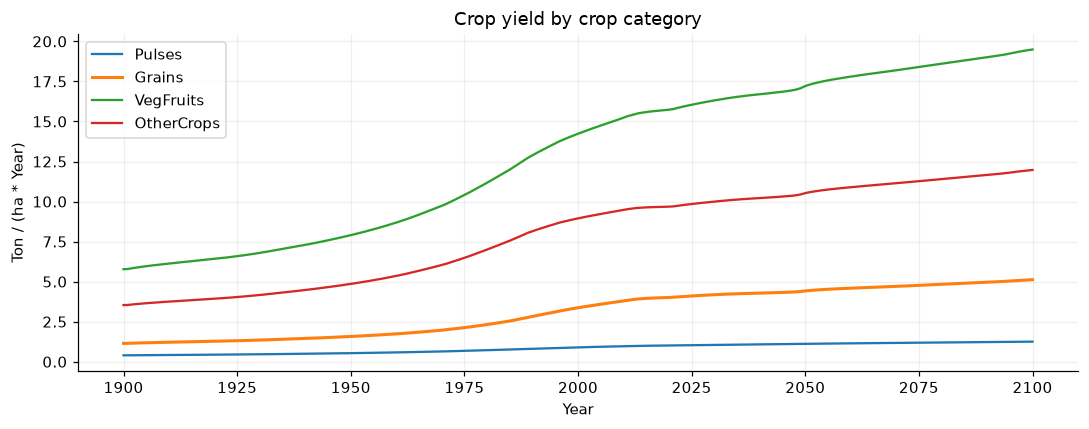

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(result.index, result["crop_yield_for_each_category[Pulses]"], label="Pulses")
plt.plot(result.index, result["crop_yield_for_each_category[Grains]"], label="Grains", linewidth=2)
plt.plot(result.index, result["crop_yield_for_each_category[VegFruits]"], label="VegFruits")
plt.plot(result.index, result["crop_yield_for_each_category[OtherCrops]"], label="OtherCrops")
plt.title("Crop yield by crop category")
plt.xlabel("Year")
plt.ylabel("Ton / (ha * Year)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Expected yield across four crop categories

`expected_crop_yield` retains the original model's delay process. This figure is separate from crop yield to distinguish the expected values from the resulting yield.

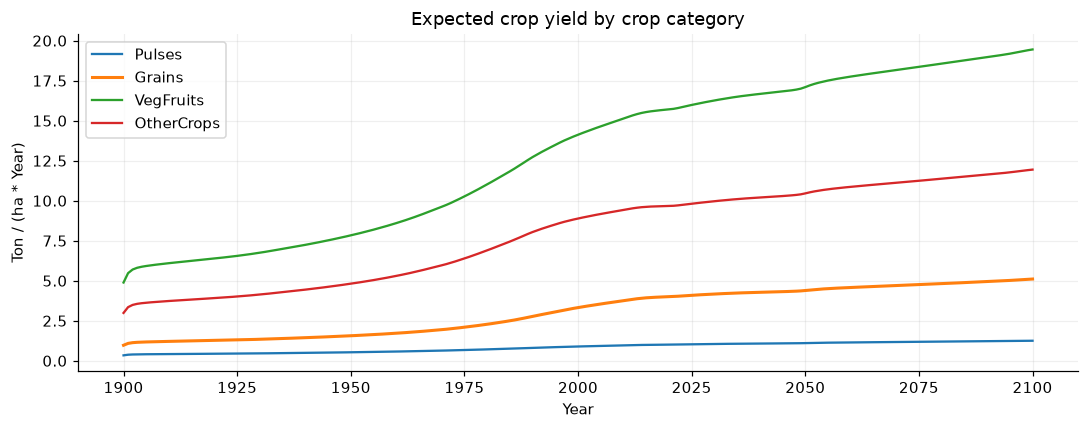

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(result.index, result["expected_crop_yield[Pulses]"], label="Pulses")
plt.plot(result.index, result["expected_crop_yield[Grains]"], label="Grains", linewidth=2)
plt.plot(result.index, result["expected_crop_yield[VegFruits]"], label="VegFruits")
plt.plot(result.index, result["expected_crop_yield[OtherCrops]"], label="OtherCrops")
plt.title("Expected crop yield by crop category")
plt.xlabel("Year")
plt.ylabel("Ton / (ha * Year)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Annual crop production

The original equation is `min(desired crop production, harvested area * crop yield)`. Production therefore does not necessarily equal area multiplied by yield.

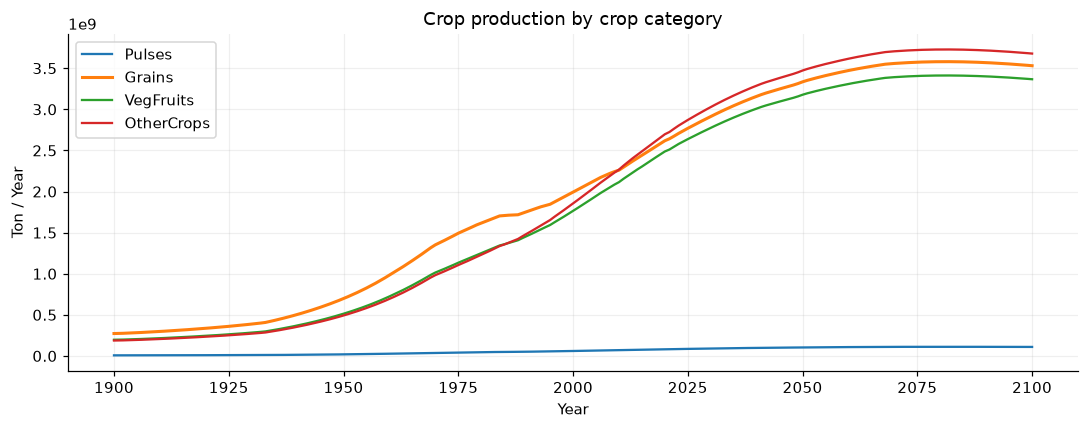

In [7]:
plt.figure(figsize=(10, 4))
plt.plot(result.index, result["production_rate_of_crops[Pulses]"], label="Pulses")
plt.plot(result.index, result["production_rate_of_crops[Grains]"], label="Grains", linewidth=2)
plt.plot(result.index, result["production_rate_of_crops[VegFruits]"], label="VegFruits")
plt.plot(result.index, result["production_rate_of_crops[OtherCrops]"], label="OtherCrops")
plt.title("Crop production by crop category")
plt.xlabel("Year")
plt.ylabel("Ton / Year")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Harvested area across four crop categories

This figure shows `Area harvested`, which should not be substituted with total cropland area.

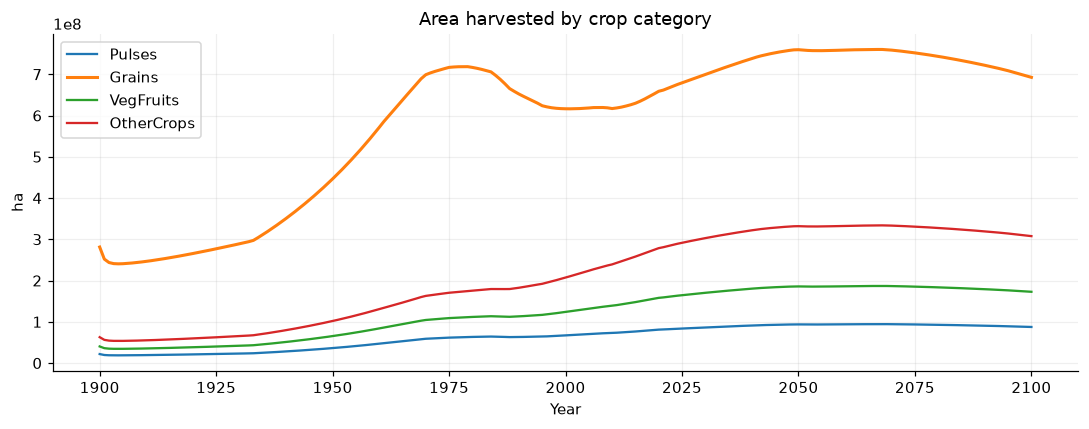

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(result.index, result["area_harvested[Pulses]"], label="Pulses")
plt.plot(result.index, result["area_harvested[Grains]"], label="Grains", linewidth=2)
plt.plot(result.index, result["area_harvested[VegFruits]"], label="VegFruits")
plt.plot(result.index, result["area_harvested[OtherCrops]"], label="OtherCrops")
plt.title("Area harvested by crop category")
plt.xlabel("Year")
plt.ylabel("ha")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Effect of fertilizer on yield

Plot the dimensionless fertilizer multiplier for each crop category. The original model uses the smaller of the nitrogen and phosphorus effects; its equation and range are preserved.

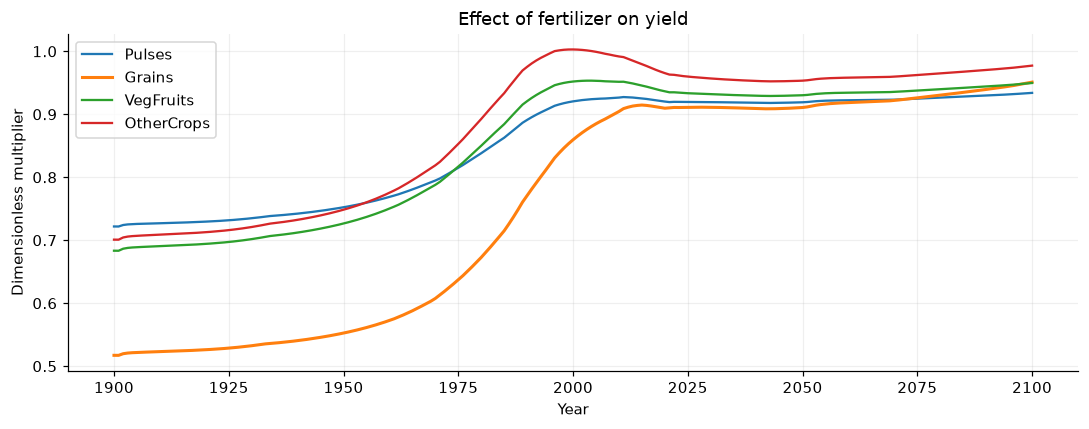

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(result.index, result["effect_of_fertilizer_on_yield[Pulses]"], label="Pulses")
plt.plot(result.index, result["effect_of_fertilizer_on_yield[Grains]"], label="Grains", linewidth=2)
plt.plot(result.index, result["effect_of_fertilizer_on_yield[VegFruits]"], label="VegFruits")
plt.plot(result.index, result["effect_of_fertilizer_on_yield[OtherCrops]"], label="OtherCrops")
plt.title("Effect of fertilizer on yield")
plt.xlabel("Year")
plt.ylabel("Dimensionless multiplier")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 9. Cropland Yield

This is the `Cropland Yield` variable shown in Vensim. It is the harvested-area-weighted mean yield across the four crop categories:

**Cropland Yield = sum of (harvested area * crop yield) across categories / total harvested area.**

It has no crop subscript and is measured in `Ton/(ha*Year)`. It differs from grain-only yield, `crop_yield_for_each_category[Grains]`. The figure shows a single trajectory under the current default parameters, without additional scenarios or historical observations.

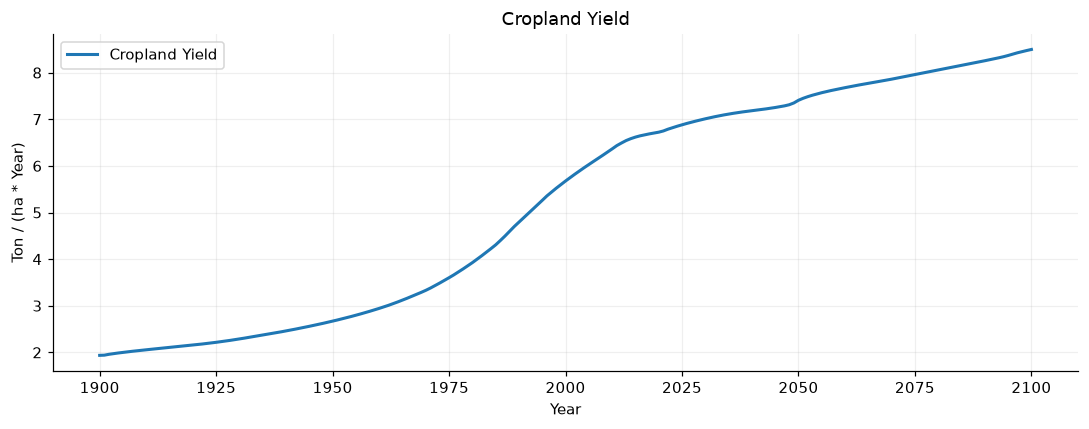

In [10]:
# Run the simulation cell in Section 2 first so result includes cropland_yield.
plt.figure(figsize=(10, 4))
plt.plot(result.index, result["cropland_yield"], label="Cropland Yield", linewidth=2)
plt.title("Cropland Yield")
plt.xlabel("Year")
plt.ylabel("Ton / (ha * Year)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()